In [ ]:
import os
import glob
import zipfile
import urllib.request
import tensorflow as tf

DATASET_URL = "https://github.com/zae-bayern/elpv-dataset/archive/refs/heads/master.zip"
ZIP_PATH = "elpv_dataset.zip"
EXTRACT_DIR = "elpv_data"

if not os.path.exists(ZIP_PATH) and not os.path.exists(EXTRACT_DIR):
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)

if not os.path.exists(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

all_pngs = glob.glob(f"{EXTRACT_DIR}/**/*.png", recursive=True)
print("Total PNG images found:", len(all_pngs))

if len(all_pngs) > 0:
    print("Sample path:", all_pngs[0])

Total PNG images found: 2624
Sample path: elpv_data/elpv-dataset-master/src/elpv_dataset/data/images/cell0931.png


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

labels_file = None
for root, dirs, files in os.walk("elpv_data"):
    if "labels.csv" in files:
        labels_file = os.path.join(root, "labels.csv")
        break

if labels_file:
    df = pd.read_csv(labels_file, sep=r'\s+|\t+|,', engine='python', header=None)
    paths_raw = df.iloc[:, 0].values
    prob = df.iloc[:, 1].values.astype(float)

    label_dict = {}
    for p, pr in zip(paths_raw, prob):
        fname = os.path.basename(str(p))
        label_dict[fname] = 1 if pr > 0.0 else 0

all_pngs = sorted(glob.glob("elpv_data/**/*.png", recursive=True))

valid_paths = []
valid_labels = []

for path in all_pngs:
    fname = os.path.basename(path)
    if fname in label_dict:
        valid_paths.append(path)
        valid_labels.append(label_dict[fname])

print(f"Matched {len(valid_paths)} images with labels.")

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [224, 224])
    img = tf.keras.applications.resnet50.preprocess_input(img)
    return img, label

dataset = tf.data.Dataset.from_tensor_slices((valid_paths, valid_labels))
dataset = dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)

val_size = int(len(valid_paths) * 0.2)
train_ds = dataset.skip(val_size).shuffle(buffer_size=1000).batch(32).prefetch(tf.data.AUTOTUNE)
val_ds = dataset.take(val_size).batch(32).prefetch(tf.data.AUTOTUNE)

base_model = tf.keras.applications.ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_phase1 = model.fit(train_ds, validation_data=val_ds, epochs=5)

Matched 2624 images with labels.
Epoch 1/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 34s 300ms/step - accuracy: 0.6738 - loss: 0.6205 - val_accuracy: 0.7500 - val_loss: 0.4967
Epoch 2/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 139ms/step - accuracy: 0.7310 - loss: 0.5399 - val_accuracy: 0.7233 - val_loss: 0.4908
Epoch 3/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.7390 - loss: 0.5201 - val_accuracy: 0.7672 - val_loss: 0.4551
Epoch 4/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 137ms/step - accuracy: 0.7314 - loss: 0.5207 - val_accuracy: 0.7691 - val_loss: 0.4321
Epoch 5/5
66/66 ━━━━━━━━━━━━━━━━━━━━ 13s 141ms/step - accuracy: 0.7671 - loss: 0.4867 - val_accuracy: 0.7405 - val_loss: 0.4600


In [ ]:
import tensorflow as tf

base_model.trainable = True

for layer in base_model.layers:
    if 'conv5' in layer.name:
        layer.trainable = True
    else:
        layer.trainable = False

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 56s 442ms/step - accuracy: 0.5414 - loss: 1.2395 - val_accuracy: 0.7366 - val_loss: 0.4879 - learning_rate: 1.0000e-05
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 187ms/step - accuracy: 0.8019 - loss: 0.4304 - val_accuracy: 0.7519 - val_loss: 0.4414 - learning_rate: 1.0000e-05
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 195ms/step - accuracy: 0.8276 - loss: 0.3910 - val_accuracy: 0.7615 - val_loss: 0.4372 - learning_rate: 1.0000e-05
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 175ms/step - accuracy: 0.8467 - loss: 0.3473 - val_accuracy: 0.7500 - val_loss: 0.4420 - learning_rate: 1.0000e-05
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 15s 178ms/step - accuracy: 0.8890 - loss: 0.2932 - val_accuracy: 0.7576 - val_loss: 0.4592 - learning_rate: 1.0000e-05
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 184ms/step - accuracy: 0.9143 - loss: 0.2355 - val_accuracy: 0.7595 - val_loss: 0.4682 - learning_rate: 2.0000e-06
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 17s 189ms/step - acc

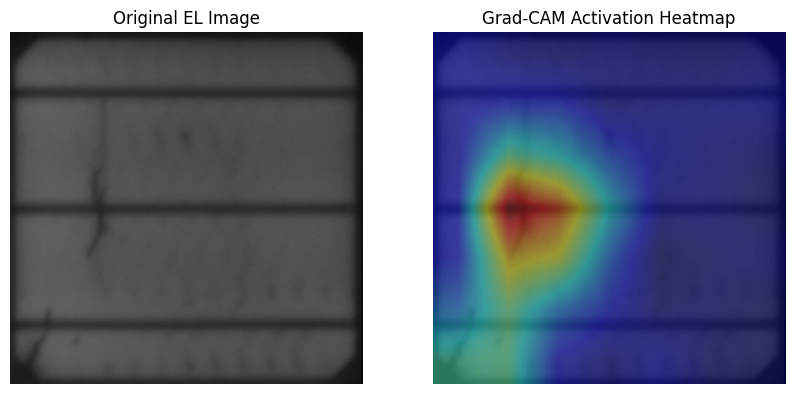

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

def make_gradcam_heatmap(img_array, model, pred_index=None):
    resnet_layer = model.get_layer('resnet50')
    last_conv_layer = resnet_layer.get_layer('conv5_block3_out')

    grad_model = tf.keras.models.Model(
        inputs=resnet_layer.inputs,
        outputs=[last_conv_layer.output, resnet_layer.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, resnet_outputs = grad_model(img_array)

        x = model.get_layer('global_average_pooling2d')(resnet_outputs)
        x = model.get_layer('dropout')(x, training=False)
        preds = model.get_layer('dense')(x)

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (224, 224))

    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    jet = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

    superimposed_img = cv2.addWeighted(img, 1 - alpha, jet, alpha, 0)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original EL Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.title("Grad-CAM Activation Heatmap")
    plt.axis("off")
    plt.show()

sample_img_path = valid_paths[0]
img = tf.io.read_file(sample_img_path)
img = tf.image.decode_png(img, channels=3)
img = tf.image.resize(img, [224, 224])
img_array = tf.expand_dims(tf.keras.applications.resnet50.preprocess_input(img), axis=0)

heatmap = make_gradcam_heatmap(img_array, model)
display_gradcam(sample_img_path, heatmap)

Classification Report:
              precision    recall  f1-score   support

   Good_Cell       0.62      0.55      0.58       158
 Faulty_Cell       0.82      0.86      0.83       366

    accuracy                           0.76       524
   macro avg       0.72      0.70      0.71       524
weighted avg       0.76      0.76      0.76       524



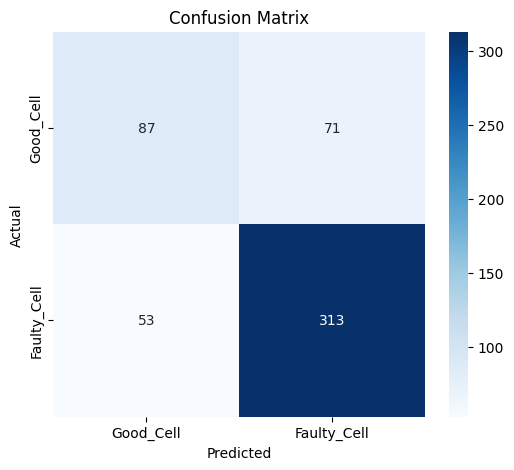

Model saved as solar_crack_detection_resnet50.h5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred_probs = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred = (y_pred_probs > 0.5).astype(int)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=["Good_Cell", "Faulty_Cell"]))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Good_Cell", "Faulty_Cell"],
            yticklabels=["Good_Cell", "Faulty_Cell"])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

model.save("solar_crack_detection_resnet50.h5")
print("Model saved as solar_crack_detection_resnet50.h5")

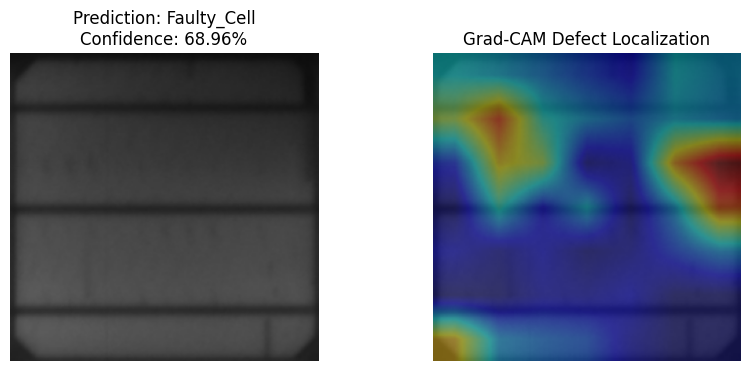

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

def predict_and_explain(img_path, model, threshold=0.5):
    raw_img = tf.io.read_file(img_path)
    decoded_img = tf.image.decode_png(raw_img, channels=3)
    resized_img = tf.image.resize(decoded_img, [224, 224])
    input_tensor = tf.expand_dims(tf.keras.applications.resnet50.preprocess_input(resized_img), axis=0)

    pred_prob = model.predict(input_tensor, verbose=0)[0][0]
    class_name = "Faulty_Cell" if pred_prob > threshold else "Good_Cell"
    confidence = pred_prob if pred_prob > threshold else (1 - pred_prob)

    resnet_layer = model.get_layer('resnet50')
    last_conv_layer = resnet_layer.get_layer('conv5_block3_out')

    grad_model = tf.keras.models.Model(
        inputs=resnet_layer.inputs,
        outputs=[last_conv_layer.output, resnet_layer.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, resnet_outputs = grad_model(input_tensor)
        x = model.get_layer('global_average_pooling2d')(resnet_outputs)
        x = model.get_layer('dropout')(x, training=False)
        preds = model.get_layer('dense')(x)
        class_channel = preds[:, 0]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    heatmap_np = heatmap.numpy()

    img = cv2.imread(img_path)
    img = cv2.resize(img, (224, 224))
    heatmap_resized = cv2.resize(heatmap_np, (224, 224))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    jet = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(img, 0.6, jet, 0.4, 0)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Prediction: {class_name}\nConfidence: {confidence*100:.2f}%")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.title("Grad-CAM Defect Localization")
    plt.axis("off")
    plt.show()

predict_and_explain(valid_paths[10], model)

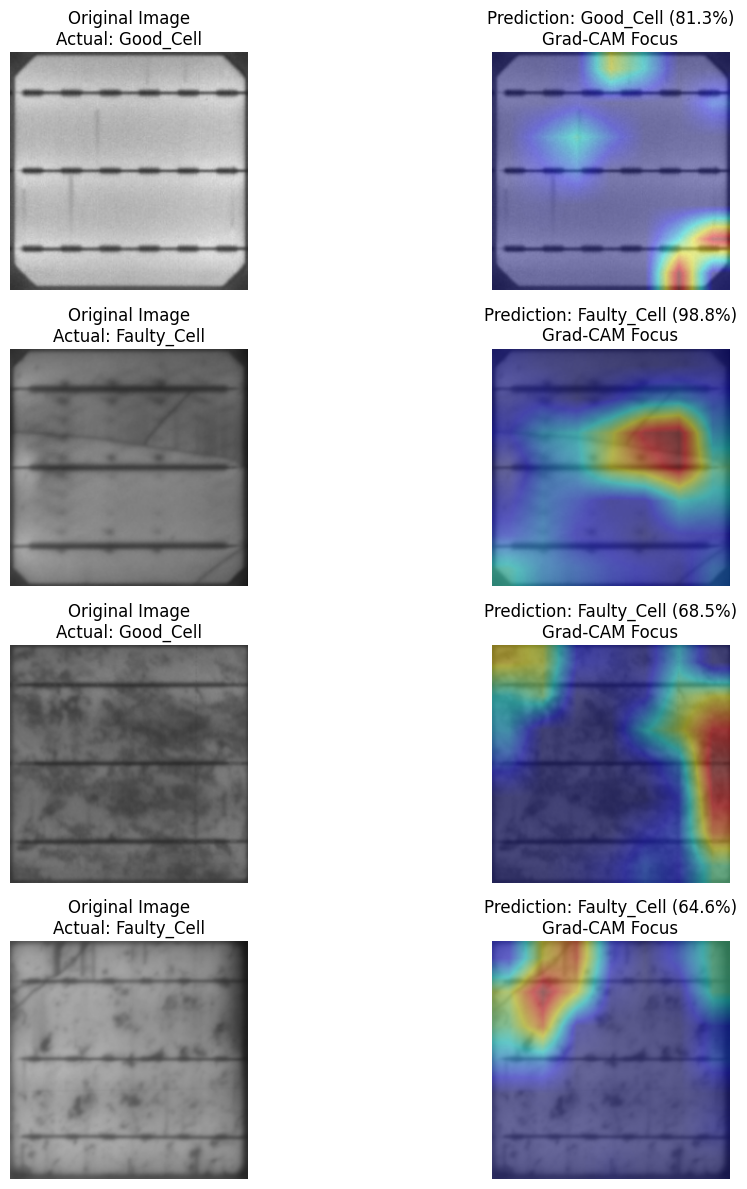

In [ ]:
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

def compare_random_samples(valid_paths, valid_labels, model, num_samples=8):
    sample_indices = random.sample(range(len(valid_paths)), num_samples)

    plt.figure(figsize=(12, 3 * num_samples))

    for i, idx in enumerate(sample_indices):
        img_path = valid_paths[idx]
        actual_label = "Faulty_Cell" if valid_labels[idx] == 1 else "Good_Cell"

        raw_img = tf.io.read_file(img_path)
        decoded_img = tf.image.decode_png(raw_img, channels=3)
        resized_img = tf.image.resize(decoded_img, [224, 224])
        input_tensor = tf.expand_dims(tf.keras.applications.resnet50.preprocess_input(resized_img), axis=0)

        pred_prob = model.predict(input_tensor, verbose=0)[0][0]
        pred_label = "Faulty_Cell" if pred_prob > 0.5 else "Good_Cell"
        confidence = pred_prob if pred_prob > 0.5 else (1 - pred_prob)

        resnet_layer = model.get_layer('resnet50')
        last_conv_layer = resnet_layer.get_layer('conv5_block3_out')

        grad_model = tf.keras.models.Model(
            inputs=resnet_layer.inputs,
            outputs=[last_conv_layer.output, resnet_layer.output]
        )

        with tf.GradientTape() as tape:
            conv_outputs, resnet_outputs = grad_model(input_tensor)
            x = model.get_layer('global_average_pooling2d')(resnet_outputs)
            x = model.get_layer('dropout')(x, training=False)
            preds = model.get_layer('dense')(x)
            class_channel = preds[:, 0]

        grads = tape.gradient(class_channel, conv_outputs)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
        conv_outputs = conv_outputs[0]
        heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
        heatmap = tf.squeeze(heatmap)
        heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)

        img = cv2.imread(img_path)
        img = cv2.resize(img, (224, 224))
        heatmap_resized = cv2.resize(heatmap.numpy(), (224, 224))
        heatmap_uint8 = np.uint8(255 * heatmap_resized)
        jet = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
        superimposed_img = cv2.addWeighted(img, 0.6, jet, 0.4, 0)

        plt.subplot(num_samples, 2, 2 * i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Original Image\nActual: {actual_label}")
        plt.axis("off")

        plt.subplot(num_samples, 2, 2 * i + 2)
        plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Prediction: {pred_label} ({confidence*100:.1f}%)\nGrad-CAM Focus")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

compare_random_samples(valid_paths, valid_labels, model, num_samples=4)